In [1]:
%load_ext autoreload

In [2]:
%autoreload 2

In [2]:
import sys
import os

module_path = os.path.abspath(os.path.join('..', ''))
if module_path not in sys.path:
    sys.path.append(module_path)

# This enables imports like
# from rect_prune_ood.lib.prunging import X
import numpy as np
from rect_prune_ood.lib.util import get_top_level_path
import matplotlib.pyplot as plt

## Plot confidences

In [37]:
id_data = np.load(get_top_level_path() + "/results/imagenet/baseline/id_imagenet.npy", allow_pickle=True).item()
ood_dtd = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_dtd.npy", allow_pickle=True).item()
ood_places = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_places.npy", allow_pickle=True).item()
ood_inat = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_inat.npy", allow_pickle=True).item()
ood_sun = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_sun.npy", allow_pickle=True).item()

In [71]:
# Find values where the prediction is correct 
def filter_correct(data):
    correct = []
    for i in range(len(data)):
        if data["prediction"][i] == data["label"][i]:
            correct.append(data["confidence"] * 100) 
    return np.concatenate(correct)

# Find values where the prediction is incorrect
id_data_correct = filter_correct(id_data)

In [72]:
id_data_bins = np.histogram(id_data_correct, bins=1000, range=(0, 100), density=False)
# ood_dtd_bins = np.histogram(ood_combined, bins=1000, range=(0, 100), density=False)

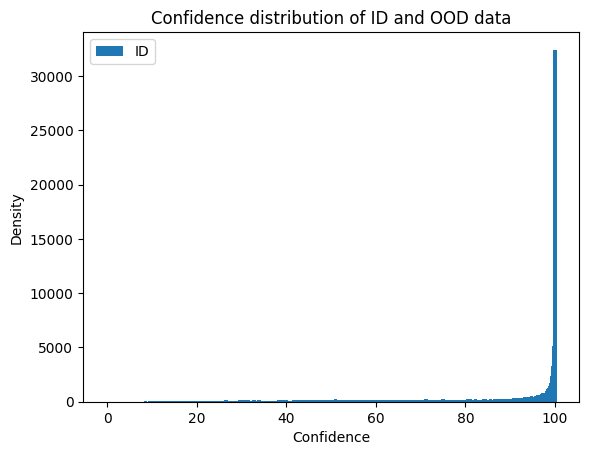

In [73]:
# Plotting the 2 distributions
# plt.bar(np.linspace(0, 100, 1000), ood_dtd_bins[0], label="OOD")
plt.bar(np.linspace(0, 100, 1000),id_data_bins[0], label="ID")
plt.legend()
plt.xlabel("Confidence")
plt.ylabel("Density")
plt.title("Confidence distribution of ID and OOD data")
plt.show()


## Plot Energy Score Distribution

In [77]:
name = "ashs"
id_data = np.load(get_top_level_path() + f"/results/imagenet/{name}/id_imagenet.npy", allow_pickle=True).item()
ood_dtd = np.load(get_top_level_path() + f"/results/imagenet/{name}/ood_dtd.npy", allow_pickle=True).item()
ood_places = np.load(get_top_level_path() + f"/results/imagenet/{name}/ood_places.npy", allow_pickle=True).item()
ood_inat = np.load(get_top_level_path() + f"/results/imagenet/{name}/ood_inat.npy", allow_pickle=True).item()
ood_sun = np.load(get_top_level_path() + f"/results/imagenet/{name}/ood_sun.npy", allow_pickle=True).item()

In [ ]:
range = 50 if name == "baseline" else 1000

In [81]:
id_bins = np.histogram(id_data["energy_score"], bins=1000, range=(0, 1000), density=False)
ood_combined_bins = np.histogram(ood_places["energy_score"], bins=1000, range=(0, 1000), density=False)

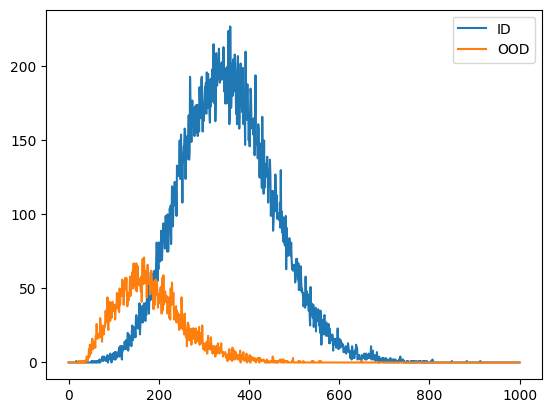

In [82]:
plt.plot(np.linspace(0, 1000, 1000), id_bins[0],  label="ID")
plt.plot(np.linspace(0, 1000, 1000), ood_combined_bins[0], label="OOD")
plt.legend()

In [83]:
# claculate the IoU of the 2 distributions

def calculate_iou(id_data, ood_data):
    id_bins = np.histogram(id_data, bins=1000, range=(0, 50), density=False)
    ood_bins = np.histogram(ood_data, bins=1000, range=(0, 50), density=False)
    intersection = np.minimum(id_bins[0], ood_bins[0]).sum()
    union = np.maximum(id_bins[0], ood_bins[0]).sum()
    return intersection / union

print(calculate_iou(id_data["energy_score"], ood_inat["energy_score"]))

0.0
